# 06 · Detecção de intrusão no Modbus

**Objetivo:** construir um IDS simples de **lista de permissão**: aprender o tráfego normal e alertar quando aparece algo novo. Requisito **SR 6.2** (monitoramento contínuo), NIST CSF **DE.CM-01**.

Por que funciona tão bem em OT? Porque o tráfego industrial é **repetitivo**: as mesmas máquinas leem os mesmos registradores com as mesmas funções o dia todo. Qualquer coisa diferente é suspeita. Produtos comerciais de monitoramento OT funcionam, no núcleo, desta forma.

**Avaliação honesta:** aprendemos no dia 1, medimos falsos positivos num dia 2 normal, e medimos detecção numa captura com ataque **rotulado** pacote a pacote.

In [1]:
# Configuração: raiz do repositório no caminho de import, tabelas largas
import sys, pathlib, logging, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
from IPython.display import Image, Markdown, display
from otsec.model import CAPTURES
from otsec import ids, inventory as inv
dia1 = inv.packets(CAPTURES / "baseline_day1.pcap")
base = ids.Baseline.learn(dia1)
base.describe()

,client,server,functions,read registers,writes,max req/s (x3)
0,127.0.20.21,127.0.10.11,read holding registers,0 to 10,never,6
1,127.0.20.21,127.0.10.12,read holding registers,0 to 10,never,6
2,127.0.20.22,127.0.10.11,write multiple registers,,"regs [100], values 348 to 576",3
3,127.0.20.23,127.0.10.11,read holding registers,0 to 20,never,6
4,127.0.20.23,127.0.10.12,read holding registers,0 to 20,never,6
5,127.0.30.31,127.0.10.11,read holding registers,0 to 10,never,3


**A linha de base em português:** HMI e SCADA só **leem** (função 3) os registradores 0 a 20; a EWS é a única que escreve, só no registrador 100 e com valores entre ~350 e ~580; nenhum cliente passa de 6 requisições por segundo (já com margem de 3x).

Repare que o historiador lendo o CLP direto também entrou na linha de base. Um IDS aprende o que **é**, não o que **deveria ser**. Por isso o exercício 02 (desenho × realidade) vem antes.

## 1. Falsos positivos num dia normal

In [2]:
dia2 = inv.packets(CAPTURES / "baseline_day2.pcap")
print("alertas no dia 2 normal:", len(ids.detect(dia2, base)))

alertas no dia 2 normal: 0


Zero. Um IDS que alerta o tempo todo é desligado em uma semana, então este é o primeiro número a olhar.

## 2. O dia do ataque

In [3]:
ataque = inv.packets(CAPTURES / "attack.pcap")
rotulos = pd.read_csv(CAPTURES / "attack_labels.csv")
print(rotulos.label.value_counts())

label
normal          4309
attack:T0814    3000
attack:T0846      34
attack:T0861      20
attack:T0888       4
attack:T0836       2
attack:T0816       2
Name: count, dtype: int64


In [4]:
alertas = ids.detect(ataque, base)
resumo = ids.summarize(alertas).assign(first=lambda d: pd.to_datetime(d["first"], unit="s").dt.strftime("%H:%M:%S.%f").str[:12])
resumo

,rule,technique,src,dst,first,count,example
0,R1 scan,T0846,127.0.40.66,many,08:03:20.079,1,5 hosts probed on 502 in 10 s
1,R2 new talker,T0886,127.0.40.66,127.0.10.11,08:03:30.000,1,127.0.40.66 never talked Modbus to 127.0.10.11
6,R3 new function,T0888,127.0.40.66,127.0.10.11,08:03:30.000,1,FC 43 (read device identification) not in baseline for this pair
2,R2 new talker,T0886,127.0.40.66,127.0.10.12,08:03:30.500,1,127.0.40.66 never talked Modbus to 127.0.10.12
7,R3 new function,T0888,127.0.40.66,127.0.10.12,08:03:30.500,1,FC 43 (read device identification) not in baseline for this pair
5,R3 new function,T0861,127.0.40.66,127.0.10.11,08:03:40.000,1510,FC 3 (read holding registers) not in baseline for this pair
8,R4 read outside map,T0861,127.0.40.66,127.0.10.11,08:03:40.000,1510,unknown client reads 0..100
4,R3 new function,T0855,127.0.40.66,127.0.10.11,08:04:00.000,1,FC 6 (write single register) not in baseline for this pair
10,R6 value out of range,T0836,127.0.40.66,127.0.10.11,08:04:00.000,1,reg 100 = 9999 by an unauthorized client
9,R5 unauthorized write,T0855,127.0.40.66,127.0.10.11,08:04:00.000,1,write to register 100 from a pair that never writes


**A sequência contada pelos alertas (mesma ordem do ataque):**

1. `R1 scan` às 08:03:20: um IP desconhecido sondou dezenas de endereços na porta 502. **T0846 Remote System Discovery.**
2. `R2 new talker` + `R3 new function` (FC 43): ele leu a identificação dos dois CLPs (fabricante, modelo, firmware). **T0888.**
3. `R4 read outside map`: varreu os registradores de 0 a 1000. Ninguém lê além de 20. **T0861 Point & Tag Identification.**
4. `R5` + `R6`: escreveu **9999** no registrador 100, de um cliente que nunca escreve. **T0855 / T0836.**
5. `R3` (FC 8): pediu diagnóstico/reinício de comunicação do CLP 2. **T0816.**
6. `R7 rate`: 1000 requisições por segundo. **T0814 Denial of Service.**

## 3. Placar contra a verdade

In [5]:
placar, totais = ids.score(alertas, rotulos, ataque)
print(totais)
placar

{'alerts': 3031, 'false_positives': 0}


,technique,attack packets,detected,rules,time to detect (s)
0,T0814,3000,True,"R3 new function, R4 read outside map, R7 rate",0.00
1,T0816,2,True,R3 new function,0.00
2,T0836,2,True,"R3 new function, R5 unauthorized write, R6 value out of range",0.00
3,T0846,34,True,R1 scan,0.08
4,T0861,20,True,"R3 new function, R4 read outside map",0.00
5,T0888,4,True,"R2 new talker, R3 new function",0.00


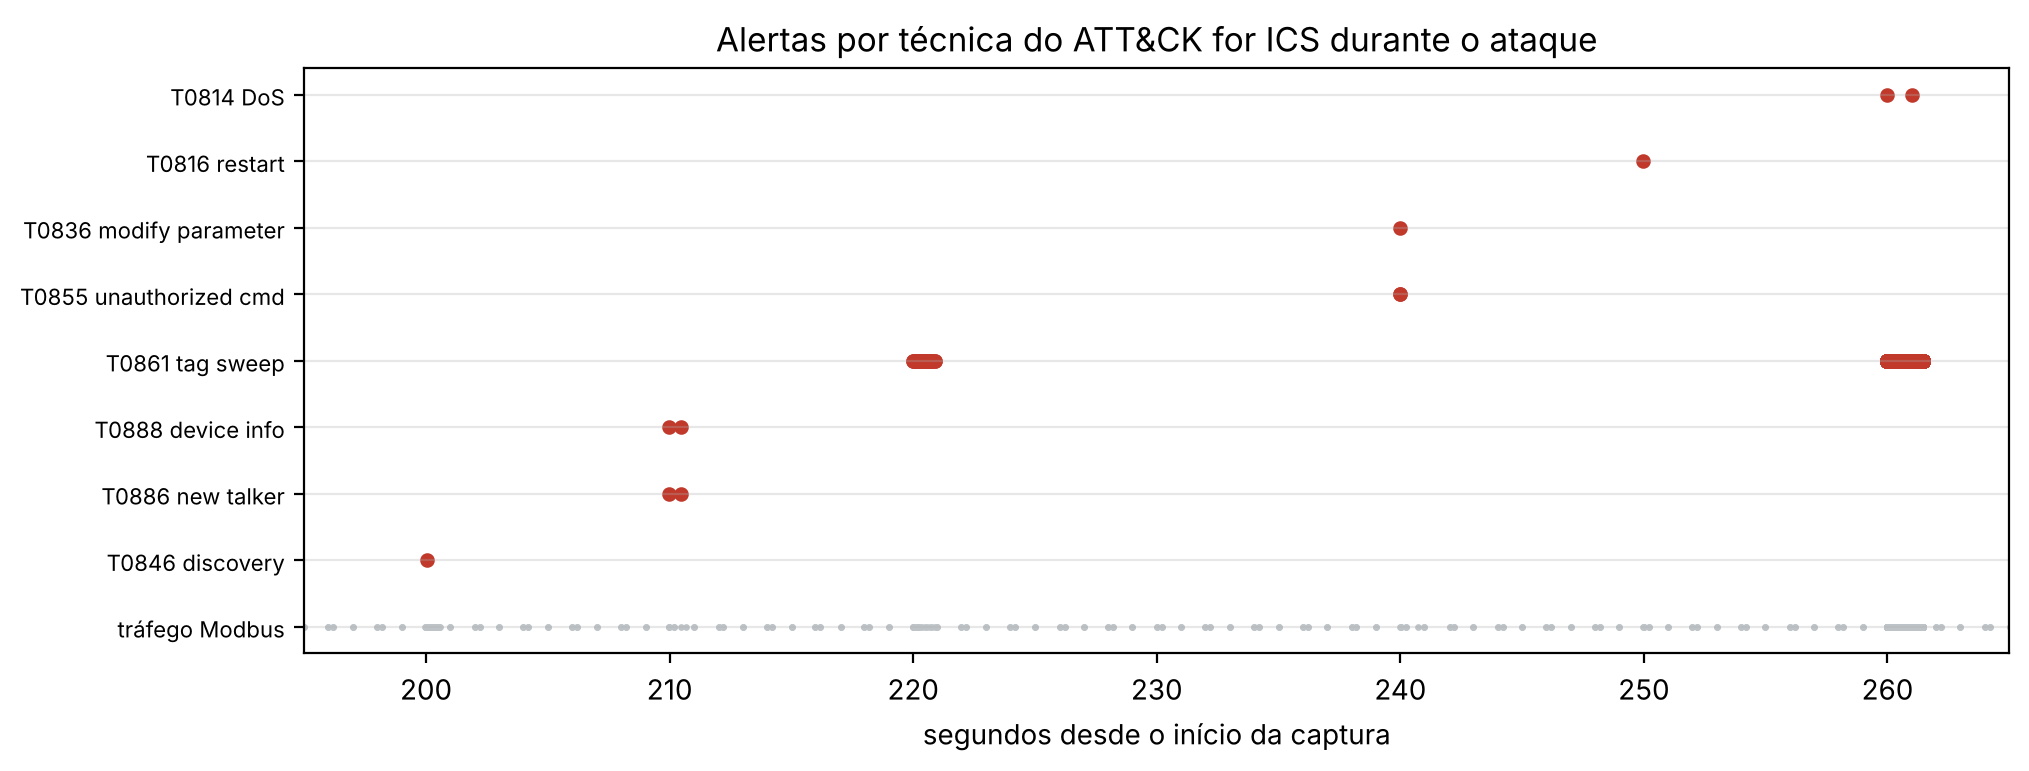

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
t0 = ataque.time.min()
normal = ataque[ataque.dport == 502]
ax.scatter(normal.time - t0, [0] * len(normal), s=2, color="#bdc3c7")
nomes = {"T0846": "T0846 discovery", "T0886": "T0886 new talker", "T0888": "T0888 device info", "T0861": "T0861 tag sweep",
         "T0855": "T0855 unauthorized cmd", "T0836": "T0836 modify parameter", "T0816": "T0816 restart", "T0814": "T0814 DoS"}
ordem = list(nomes)
for tec, g in alertas.groupby("technique"):
    ax.scatter(g.time - t0, [1 + ordem.index(tec)] * len(g), s=18, color="#c0392b")
ax.set_yticks(range(len(ordem) + 1), ["tráfego Modbus"] + [nomes[t] for t in ordem], fontsize=8)
ax.set_xlim(195, 265); ax.set_xlabel("segundos desde o início da captura")
ax.set_title("Alertas por técnica do ATT&CK for ICS durante o ataque"); ax.grid(axis="y", alpha=.3)
from otsec import figures; figures.save(fig, "ids_timeline"); plt.show()

**Todas as seis técnicas detectadas, zero falsos positivos, detecção no primeiro pacote** de cada fase (a varredura leva 80 ms porque o alerta só dispara a partir de 5 hosts sondados).

**Limites que é preciso conhecer:**

* Um atacante que usa o **próprio EWS** (credencial roubada) e grava um valor **dentro** da faixa normal passa despercebido. Contra isso: controle de mudanças, janela de manutenção e alerta para escrita fora de horário.
* A linha de base aprendeu o historiador lendo o CLP direto. Linha de base precisa de **revisão humana** antes de virar referência.
* Aqui o IDS roda sobre capturas. Em produção, ele leria de uma porta espelhada (SPAN) do switch, só escutando.

## Resumo

* Allowlist é o modelo natural para OT: poucos padrões, muito estáveis.
* Medir com **dados rotulados** e com um **dia normal separado** é o que dá credibilidade ao detector.
* Evidência do controle `CTL-IDS`: `tests/test_ids.py`.